# Generate and test in a fully connected network

Fully connected, our method from `../01_distractors.ipynb` never mixes the two tasks, but it splits the hidden units
between them unevenly early on and never revises the split, so it ends far above the ideal connectivity
(`../04_fully_connected.ipynb`). Generate and test lets the network revise the split: every so often, its least used
hidden unit starts over as a new unit, which a task with too few units can then take. This notebook adds a simple
generate and test to our method, and asks how close it gets to the ideal connectivity and how that depends on the time
between resets.

**Problem.** As in `../04_fully_connected.ipynb`: 2-task simple multi-GEOFF. Each task is a teacher with 21 inputs,
10 zero-threshold LTUs and 10 linear outputs, with $N(0, 1)$ noise added to each output. The inputs and every teacher
weight are random $\pm 1$ signs, so each LTU fires with probability 1/2 and each output's signal has variance about
2.5. Every 1000 steps, one task (chosen at random) has the columns of its output weights permuted.

**Networks.** 42 inputs → 20 LTU hidden units → 20 linear outputs, each layer with a bias.
- *Fully connected*: every hidden unit reads every input and feeds every output.
- *Ideal connectivity*: 10 hidden units per task, each reading only its own task's inputs and feeding only its own
  task's outputs.

**Learner.** Ours, as in `../04_fully_connected.ipynb`: Autostep with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and
$\tau = 10^4$, centered hidden units with a matching centered backward pass, input weights starting at
$U(-\alpha_0, \alpha_0)$, and output weights and biases starting at 0. Every run uses it.

**Generate and test.** Every reset period, the hidden unit with the smallest mean $|$output weight$|$ starts over as a
new unit: output weights 0, input weights $U(-\alpha_0, \alpha_0)$, step-sizes $\alpha_0$, zero Autostep traces, and its
running means at their initial values. Only the fully connected network uses it.

**Question 1**: how close does generate and test bring the fully connected network to the ideal connectivity? Runs:
the fully connected network with and without resets every 100k steps, and the ideal connectivity. 100k is the best of
the periods tried on 2-task multi-MNIST (`multi_mnist.ipynb`). The two runs without generate and test are those of
`../04_fully_connected.ipynb`. 1M steps and 30 seeds; seed $s$ gives every run the same teacher, perturbations and
initial-weight draw.
- **H1**, generate and test helps: with it, the fully connected network is more than 1% below itself without it.
- **H2**, generate and test reaches the ideal: with it, the fully connected network is at most 1% above the ideal
  connectivity.

The hypotheses are on the excess MSE (above the noise floor) averaged over the last 10% of training, pooled over
seeds, with gaps taken per seed relative to the reference run's mean.

**Question 2**: how does generate and test depend on the reset period? The fully connected network with resets every
10k, 20k, 50k, 100k and 200k steps, on the first 5 seeds, against the first 5 seeds of Question 1's runs without
generate and test. This sweep shows sensitivity; it has no hypothesis.

**Diagnostics**, fixed in advance, for the fully connected runs, as in `../04_fully_connected.ipynb`:
1. *Path purity*: the share of all input → hidden → output path weight (the product of $|w|$ along the path) that
   starts and ends in the same task. 1 means no path crosses tasks; 1/2 that the units mix the tasks evenly.
2. *Allocation*: how evenly the hidden units are split between the tasks, counting each unit for the task whose outputs
   it feeds most. 1 means 10 units each; 0 means all 20 feed one task. A new unit's output weights are near 0, so it
   counts for whichever task they happen to favour, which makes allocation noisy by about one unit.

The learning curves show the RMSE over outputs (its minimum, the noise, is 1): mean $\pm$ 2 SE over seeds in
Question 1, and the mean alone in Question 2. Everything is recorded at step 1, then averaged over each window of 4000
steps.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd
from phd.jax_core.tasks.simple_multi_geoff import SimpleMultiGEOFFTask
from phd.jax_core.utils import stack_pytrees

sns.set_theme('notebook', 'whitegrid')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [ ]:
# --- Problem ---
N_TASKS = 2
N_INPUTS_PER_TASK = 21
N_TEACHER_LTUS_PER_TASK = 10
N_OUTPUTS_PER_TASK = 10
NOISE_STD = 1.0
PERTURB_PERIOD = 1000                # steps between perturbations, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 10               # the ideal network's units per task; the fully connected one has as many in total

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means

# --- Generate and test ---
REINIT_PERIOD = 100_000              # Question 1: steps between resets of the unit with the smallest output weights
SWEEP_PERIODS = (10_000, 20_000, 50_000, 100_000, 200_000)      # Question 2
SWEEP_SEEDS = 5                      # Question 2 runs the first 5 seeds

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 250                      # each window records the mean of the loss, path purity and allocation

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # the loss is compared over the last 10% of training ...
LOSS_TOLERANCE = 0.01                # ... with this relative tolerance

In [3]:
LAYERS = ('w1', 'w2')
N_HIDDEN = N_TASKS * N_HIDDEN_PER_TASK
N_OUTPUTS = N_TASKS * N_OUTPUTS_PER_TASK

input_task = np.repeat(np.arange(N_TASKS), N_INPUTS_PER_TASK)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_OUTPUTS_PER_TASK)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum()} weights' for k in LAYERS))

ideal connectivity: w1 420 weights, w2 200 weights
fully connected: w1 840 weights, w2 400 weights


## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight


def init_learner(key, masks):
    # Input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights and biases 0.
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * INIT_STEP_SIZE * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    return Learner(w, OPTIMIZER.init(w), jnp.full(N_HIDDEN, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25))


def forward(w, x, learner, masks):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
    # correction leaves the value unchanged.
    correction = jnp.sum(slope * w1, axis=1)
    h = h - mean - correction + jax.lax.stop_gradient(correction)

    h = jnp.append(h, 1.0)
    y_hat = (w['w2'] * masks['w2']) @ h
    return y_hat, ({'w1': x[None], 'w2': h[None]}, mean, slope)


def learner_step(learner, x, y, masks):
    # One online Autostep update. Returns the new learner and the squared error summed over outputs.
    def loss_fn(w):
        y_hat, aux = forward(w, x, learner, masks)
        return 0.5 * jnp.sum((y_hat - y) ** 2), aux

    (loss, (source_values, mean, slope)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return Learner(w, opt, mean, slope), 2.0 * loss


def generate_and_test(learner, key, step, period, masks):
    # Every `period` steps, the hidden unit with the smallest mean |output weight| starts over as a new unit: its
    # weights, step-sizes, Autostep traces and running means are set to those of a freshly initialized network (output
    # weights 0, input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE)).
    unit = jnp.argmin(jnp.abs(learner.w['w2'][:, :-1]).mean(0))
    fresh = init_learner(jax.random.fold_in(key, step), masks)
    is_unit = jnp.arange(N_HIDDEN) == unit
    parts = {'w1': is_unit[:, None], 'w2': jnp.append(is_unit, False)[None, :]}     # the unit's row of w1, column of w2
    pick = lambda new, old: {k: jnp.where(parts[k], new[k], old[k]) for k in LAYERS}
    opt = learner.opt
    reset = learner._replace(
        w=pick(fresh.w, learner.w),
        opt=opt._replace(beta=pick(fresh.opt.beta, opt.beta), h=pick(fresh.opt.h, opt.h), v=pick(fresh.opt.v, opt.v)),
        hidden_mean=jnp.where(is_unit, fresh.hidden_mean, learner.hidden_mean),
        hidden_slope=jnp.where(is_unit[:, None], fresh.hidden_slope, learner.hidden_slope))
    return jax.tree.map(lambda new, old: jnp.where(step % period == 0, new, old), reset, learner)

## Training

In [5]:
WINDOW = NUM_STEPS // N_WINDOWS


def diagnostics(w):
    # Path purity: the share of all input -> hidden -> output path weight (the product of |w| along the path) that
    # starts and ends in the same task. Allocation: how evenly the hidden units are split between the tasks, counting
    # each unit for the task whose outputs it feeds most; 1 when every task has the same number, 0 when all units feed
    # one task. Biases are left out.
    # Inputs and outputs are laid out task by task, so (unit, task) sums are reshapes.
    reads = jnp.abs(w['w1'][:, :-1]).reshape(N_HIDDEN, N_TASKS, -1).sum(2)       # |w| into each unit from each task
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, -1, N_HIDDEN).sum(1).T     # |w| out of each unit to each task
    units = (feeds.argmax(1)[:, None] == np.arange(N_TASKS)).sum(0)              # hidden units per task
    return {'path purity': (reads * feeds).sum() / (reads.sum(1) * feeds.sum(1)).sum(),
            'allocation': (1 - units.max() / N_HIDDEN) / (1 - 1 / N_TASKS)}


def train(key, task, masks, reinit_period=None):
    # Step 1 on its own, then NUM_STEPS online steps in windows, with generate and test every `reinit_period` steps (if
    # given). Returns the per-output MSE, and the path purity and allocation: at step 1, then averaged over every window.
    def one_step(carry, _):
        learner, task, total = carry
        task, (x, y) = task.generate_batch(1)
        learner, sq_err = learner_step(learner, x[0], y[0], masks)
        if reinit_period is not None:
            learner = generate_and_test(learner, key, task.step, reinit_period, masks)
        total = jax.tree.map(jnp.add, total, diagnostics(learner.w))
        return (learner, task, total), sq_err

    def window(carry, _):
        learner, task = carry
        zeros = jax.tree.map(jnp.zeros_like, diagnostics(learner.w))
        (learner, task, total), sq_err = jax.lax.scan(one_step, (learner, task, zeros), length=WINDOW)
        return (learner, task), (sq_err.mean() / N_OUTPUTS, jax.tree.map(lambda t: t / WINDOW, total))

    task, (x, y) = task.generate_batch(1)
    learner, sq_err = learner_step(init_learner(key, masks), x[0], y[0], masks)
    _, (mse, values) = jax.lax.scan(window, (learner, task), length=N_WINDOWS)
    first = (sq_err / N_OUTPUTS, diagnostics(learner.w))
    return jax.tree.map(lambda f, v: jnp.concatenate([f[None], v]), first, (mse, values))


def seeds(n_seeds):
    # Init keys and teachers for the first n_seeds seeds. Seed s uses teacher s (and its perturbations) and init key s
    # for every run, so runs are paired.
    tasks = stack_pytrees([
        SimpleMultiGEOFFTask(N_TASKS, perturb_period=PERTURB_PERIOD, n_features_per_task=N_INPUTS_PER_TASK,
                             n_hidden_per_task=N_TEACHER_LTUS_PER_TASK, n_outputs_per_task=N_OUTPUTS_PER_TASK,
                             noise_std=NOISE_STD, seed=s)
        for s in range(n_seeds)])
    return jax.random.split(jax.random.PRNGKey(0), N_SEEDS)[:n_seeds], tasks


def run(network, reinit_period=None, n_seeds=N_SEEDS):
    # Trains ours on `network` (a key of MASKS) on the first n_seeds seeds, vmapped into one scan, with generate and test
    # every `reinit_period` steps (if given). A list of periods runs each of them, also vmapped, and adds a leading period
    # axis. Returns the excess MSE, the RMSE, the path purity and the allocation, each (seed, step 1 + window).
    keys, tasks = seeds(n_seeds)
    train_seeds = jax.vmap(lambda key, task, period: train(key, task, MASKS[network], period), in_axes=(0, 0, None))
    if isinstance(reinit_period, list):
        train_seeds = jax.vmap(train_seeds, in_axes=(None, None, 0))
        reinit_period = jnp.array(reinit_period)
    mse, values = jax.jit(train_seeds)(keys, tasks, reinit_period)
    mse = np.asarray(mse)
    return {'excess_mse': mse - NOISE_STD ** 2, 'rmse': np.sqrt(mse), **jax.tree.map(np.asarray, values)}

## Question 1: generate and test every 100k steps

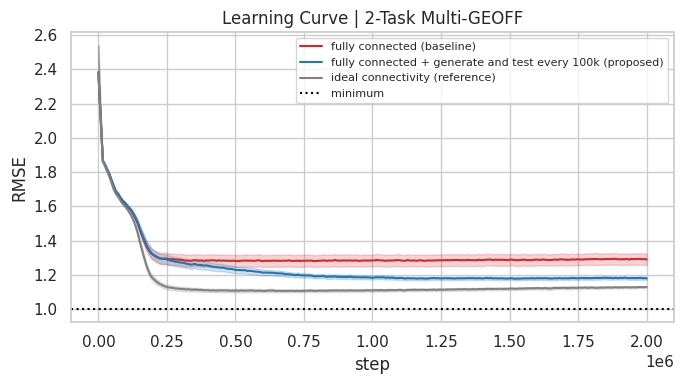

fully connected (baseline)                                     excess MSE 0.6767
fully connected + generate and test every 100k (proposed)      excess MSE 0.3963
ideal connectivity (reference)                                 excess MSE 0.2695
H1, generate and test vs fully connected: -41.4% (± 12.0%): held
H2, generate and test vs ideal connectivity: +47.1% (± 10.0%): failed


In [6]:
GNT = f'fully connected + generate and test every {REINIT_PERIOD // 1000}k (proposed)'
BASELINE = 'fully connected (baseline)'
IDEAL = 'ideal connectivity (reference)'
runs = {BASELINE: run('fully connected'),
        GNT: run('fully connected', REINIT_PERIOD),
        IDEAL: run('ideal connectivity')}
COLORS = {BASELINE: 'tab:red', GNT: 'tab:blue', IDEAL: 'gray'}

STEPS = 1 + np.arange(N_WINDOWS + 1) * WINDOW     # step 1, then the end of every window
plt.figure(figsize=(7, 4))
for label, res in runs.items():
    mean = res['rmse'].mean(0)
    sem = res['rmse'].std(0) / np.sqrt(N_SEEDS)
    plt.plot(STEPS, mean, color=COLORS[label], lw=1.5, label=label)
    plt.fill_between(STEPS, mean - 2 * sem, mean + 2 * sem, color=COLORS[label], alpha=0.2)
plt.axhline(NOISE_STD, color='black', lw=1.5, ls=':', label='minimum')
plt.xlabel('step')
plt.ylabel('RMSE')
plt.title('Learning Curve | 2-Task Multi-GEOFF')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Each seed's excess MSE over the last FINAL_FRACTION of training.
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)
loss = {label: res['excess_mse'][:, final].mean(1) for label, res in runs.items()}
for label, l in loss.items():
    print(f'{label:<62} excess MSE {l.mean():.4f}')


def gap(label, reference):
    # The per-seed gap of `label` to `reference` on the same seed, relative to the reference's mean: its mean and 2 SE.
    g = (loss[label] - loss[reference]) / loss[reference].mean()
    return g.mean(), 2 * g.std() / np.sqrt(N_SEEDS)


held = lambda ok: 'held' if ok else 'failed'
h1, h1_se = gap(GNT, BASELINE)
h2, h2_se = gap(GNT, IDEAL)
print(f'H1, generate and test vs fully connected: {h1:+.1%} (± {h1_se:.1%}): {held(h1 < -LOSS_TOLERANCE)}')
print(f'H2, generate and test vs ideal connectivity: {h2:+.1%} (± {h2_se:.1%}): {held(h2 <= LOSS_TOLERANCE)}')

### Diagnostics: mixing and unit allocation

Path purity and allocation over training for the fully connected runs (mean $\pm$ 2 SE over seeds).

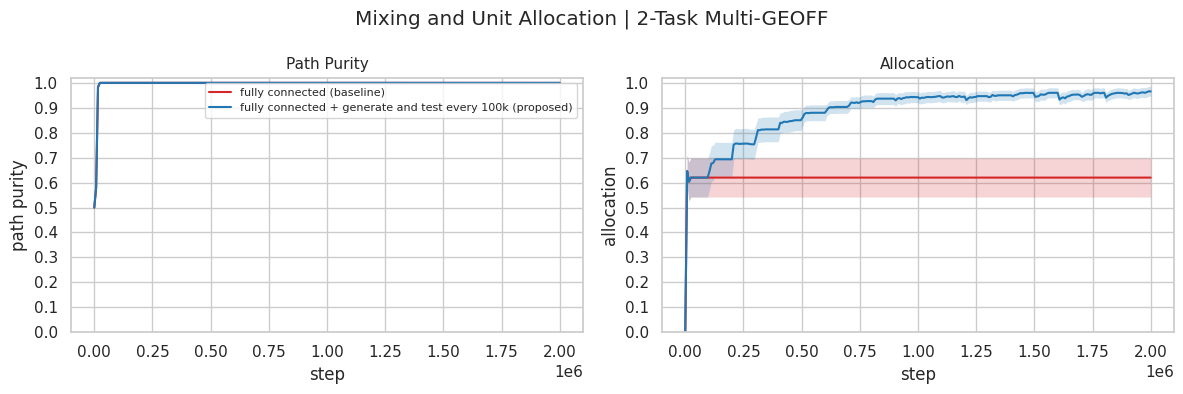

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, quantity in zip(axes, ('path purity', 'allocation')):
    for label in (BASELINE, GNT):
        v = runs[label][quantity]                                                                   # (seed, step)
        mean, sem = v.mean(0), v.std(0) / np.sqrt(N_SEEDS)
        ax.plot(STEPS, mean, color=COLORS[label], lw=1.5, label=label)
        ax.fill_between(STEPS, mean - 2 * sem, mean + 2 * sem, color=COLORS[label], alpha=0.2, lw=0)
    ax.set_ylim(0, 1.02)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
    ax.set_xlabel('step')
    ax.set_ylabel(quantity)
    ax.set_title(quantity.title(), fontsize=11)
axes[0].legend(fontsize=8)
fig.suptitle('Mixing and Unit Allocation | 2-Task Multi-GEOFF')
fig.tight_layout()
plt.show()

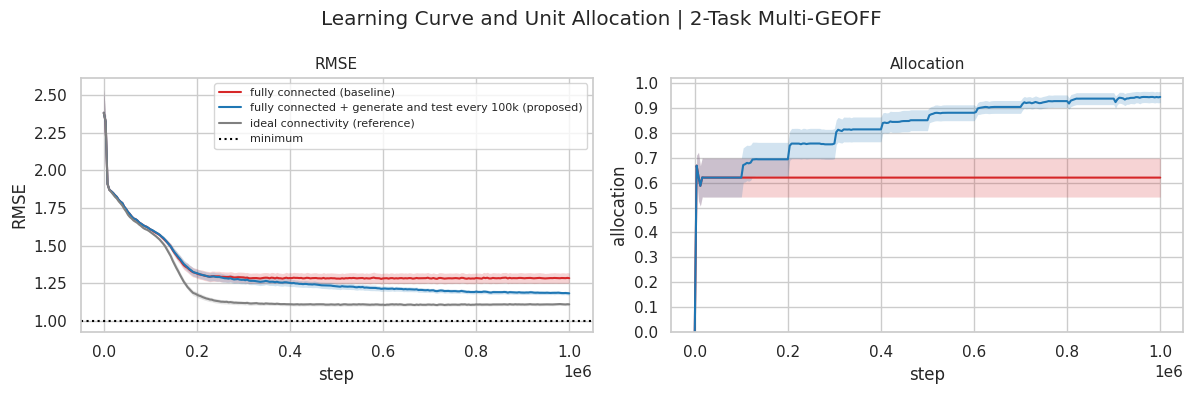

In [ ]:
# Temporary: the learning curve and the allocation side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, quantity, labels in ((axes[0], 'rmse', runs), (axes[1], 'allocation', (BASELINE, GNT))):
    for label in labels:
        v = runs[label][quantity]                                                                   # (seed, step)
        mean, sem = v.mean(0), v.std(0) / np.sqrt(N_SEEDS)
        ax.plot(STEPS, mean, color=COLORS[label], lw=1.5, label=label)
        ax.fill_between(STEPS, mean - 2 * sem, mean + 2 * sem, color=COLORS[label], alpha=0.2, lw=0)
    ax.set_xlabel('step')
axes[0].axhline(NOISE_STD, color='black', lw=1.5, ls=':', label='minimum')
axes[0].set_ylabel('RMSE')
axes[0].set_title('RMSE', fontsize=11)
axes[0].legend(fontsize=8)
axes[1].set_ylim(0, 1.02)
axes[1].yaxis.set_major_locator(plt.MultipleLocator(0.1))
axes[1].set_ylabel('allocation')
axes[1].set_title('Allocation', fontsize=11)
fig.suptitle('Learning Curve and Unit Allocation | 2-Task Multi-GEOFF')
fig.tight_layout()
plt.show()

## Question 2: the reset period

The fully connected network with generate and test at every reset period, on the first 5 seeds, with the first 5 seeds
of Question 1's runs without generate and test (mean over seeds).

In [ ]:
sweep = run('fully connected', list(SWEEP_PERIODS), SWEEP_SEEDS)     # each record is (period, seed, step 1 + window)
sweep_runs = {f'fully connected + generate and test every {p // 1000}k (proposed)': jax.tree.map(lambda v: v[i], sweep)
              for i, p in enumerate(SWEEP_PERIODS)}
sweep_colors = dict(zip(sweep_runs, sns.color_palette('Blues', len(SWEEP_PERIODS) + 1)[1:]))
sweep_runs.update({label: jax.tree.map(lambda v: v[:SWEEP_SEEDS], runs[label]) for label in (BASELINE, IDEAL)})
sweep_colors.update({BASELINE: COLORS[BASELINE], IDEAL: COLORS[IDEAL]})

plt.figure(figsize=(7, 4))
for label, res in sweep_runs.items():
    plt.plot(STEPS, res['rmse'].mean(0), color=sweep_colors[label], lw=1.5, label=label)
plt.axhline(NOISE_STD, color='black', lw=1.5, ls=':', label='minimum')
plt.xlabel('step')
plt.ylabel('RMSE')
plt.title('Reset Period | 2-Task Multi-GEOFF')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

for label, res in sweep_runs.items():
    print(f'{label:<62} excess MSE {res["excess_mse"][:, final].mean():.4f}, '
          f'allocation {res["allocation"][:, final].mean():.2f}')

## Results

- **H1 held.** With resets every 100k steps, the fully connected network's excess MSE is 38% (± 12%, 2 SE over paired
  seeds) below its own without generate and test: 0.407 against 0.656.
- **H2 failed.** It is still 77% (± 14%) above the ideal connectivity (0.230), and still falling at 1M steps.
- **Diagnostics.** Path purity stays at 1. Allocation rises in a step at almost every reset, from 0.62 to 0.94 by 1M
  steps, so generate and test does move units to the task that has too few, one per reset. The loss lags behind the
  allocation; a likely cause, not tested, is that each new unit starts with every step-size at $\alpha_0$ and takes
  a long time to become useful.
- **Reset period** (Question 2, 5 seeds). Excess MSE falls as the period grows up to 100k: 0.83, 0.73, 0.56, 0.44 and
  0.49 with resets every 10k, 20k, 50k, 100k and 200k steps, against 0.74 without generate and test and 0.26 with the
  ideal connectivity on the same seeds. Every 10k steps is worse than no generate and test, and its allocation stays
  where it was (0.56 against 0.54), likely because each new unit is reset again before it gets going. Every 200k
  steps, with half as many resets, ends a little behind every 100k.